In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

emploi = pd.read_csv("DS_RP_EMPLOI_LR_COMP_2023_data.csv",sep=";",dtype={"GEO": str,"EMPSTA_ENQ":str})
emploi = emploi [['TIME_PERIOD','EMPSTA_ENQ','GEO_OBJECT','GEO','OBS_VALUE','PCS']]

emploi_dep = emploi.loc[emploi["GEO_OBJECT"] == "DEP"]
emploi_dep = emploi_dep.loc[emploi_dep["PCS"] == "_T"]
emploi_dep = emploi_dep.loc[emploi_dep["TIME_PERIOD"] == 2023]

emploi_dep = emploi_dep.pivot(index="GEO", columns="EMPSTA_ENQ", values="OBS_VALUE")
emploi_dep.head()


EMPSTA_ENQ,1,1T2,2
GEO,,,
01,306353.92376,332062.20638,25708.28261
02,198151.87740,227038.54348,28886.66608
03,124010.40923,138249.81493,14239.40570
04,64198.24881,71219.69936,7021.45055
05,59286.34693,64156.11979,4869.77287


Le jeu provient de : https://www.data.gouv.fr/datasets/population-active-et-chomage-principaux-indicateurs-dossier-complet-1

In [28]:
emploi_dep["Taux d'activité"]=emploi_dep["1"]/emploi_dep['1T2']

emploi_dep= emploi_dep.drop(columns=["1","2"])
emploi_dep=emploi_dep.reset_index()

emploi_dep.columns.tolist()

emploi_dep=emploi_dep.rename(columns = {"1T2":"Population active","GEO":"Département"})
emploi_dep.head()


EMPSTA_ENQ,Département,Population active,Taux d'activité
0,01,332062.20638,0.922580
1,02,227038.54348,0.872768
2,03,138249.81493,0.897002
3,04,71219.69936,0.901411
4,05,64156.11979,0.924095


In [36]:
emploi_dep.sort_values(by="Taux d'activité").head()

EMPSTA_ENQ,Département,Population active,Taux d'activité
99,974,376034.03759,0.787271
96,971,157368.88831,0.820405
66,66,198806.49500,0.852335
97,972,152661.14323,0.856454
98,973,92071.64531,0.860825


Les données de bac proviennent de : https://www.data.gouv.fr/datasets/indicateurs-de-valeur-ajoutee-des-lycees-denseignement-general-et-technologique-ancienne-version 

In [35]:
bac = pd.read_csv("fr-en-indicateurs-de-resultat-des-lycees-denseignement-general-et-technologique.csv",sep=";")

bac["Nombre de réussites"] = bac["Presents - Toutes series"]*bac["Taux de reussite - Toutes series"]/100
bac["Nombre de mentions"] = bac["Presents - Toutes series"]*bac["Taux de mentions - Toutes series"]/100
bac["Nombre acces 2nde-bac pondéré"] = bac["Taux d'acces 2nde-bac"]*bac["Presents - Toutes series"]/100

bac = bac.groupby(["Code departement","Annee"]).agg({"Presents - Toutes series":"sum",
                                               "Effectif de seconde":"sum",
                                               "Effectif de premiere":"sum",
                                               "Effectif de terminale":"sum",
                                               "Nombre de réussites":"sum",
                                               "Nombre de mentions":"sum",
                                               "Nombre acces 2nde-bac pondéré":"sum"})

bac["Taux de réussite"] = bac["Nombre de réussites"]/bac["Presents - Toutes series"]
bac["Taux de mentions"] = bac["Nombre de mentions"]/bac["Presents - Toutes series"]
bac["Taux de passage 2nde - bac"] = bac["Nombre acces 2nde-bac pondéré"]/bac["Presents - Toutes series"]

bac = bac.drop(columns = ["Nombre de réussites","Nombre de mentions","Nombre acces 2nde-bac pondéré"])

bac= bac.reset_index()
bac.head()

/tmp/ipykernel_5048/350392379.py:1: DtypeWarning: Columns (47: Taux de reussite attendu france - L, 48: Taux de reussite attendu france - ES, 49: Taux de reussite attendu france - S, 51: Taux de reussite attendu france - STI2D, 52: Taux de reussite attendu france - STD2A, 53: Taux de reussite attendu france - STMG, 55: Taux de reussite attendu france - STL, 56: Taux de reussite attendu france - ST2S, 57: Taux de reussite attendu france - TMD, 58: Taux de reussite attendu france - STHR, 59: Taux de reussite attendu france - Toutes series, 71: Taux de mentions attendu - L, 72: Taux de mentions attendu - ES, 73: Taux de mentions attendu - S, 74: Taux de mentions attendu - STI2D, 75: Taux de mentions attendu - STD2A, 76: Taux de mentions attendu - STMG, 77: Taux de mentions attendu - STL, 78: Taux de mentions attendu - ST2S, 79: Taux de mentions attendu - TMD, 80: Taux de mentions attendu - STHR, 81: Taux de mentions attendu - Toutes series, 83: Structure pedagogique 7 groupes, 95: Taux d'

,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac
0,01,2012,3628,4383.0,3688.0,0.0,0.915474,0.0,0.737643
1,01,2013,3665,4495.0,3926.0,0.0,0.937465,0.0,0.758963
2,01,2014,3577,4601.0,4074.0,0.0,0.932586,0.0,0.763229
3,01,2015,3852,4893.0,4185.0,4083.0,0.934772,0.0,0.780132
4,01,2016,4035,4736.0,4528.0,4261.0,0.923244,0.0,0.772491


In [34]:
bac_2023 = bac[bac["Annee"]==2023]

bac_2023.head()

,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac
11,01,2023,4713,5085.0,4679.0,4804.0,0.947836,0.606446,0.843747
23,02,2023,3388,3801.0,3476.0,3450.0,0.933999,0.546975,0.826077
35,03,2023,1951,2123.0,1855.0,2034.0,0.950661,0.559047,0.833203
47,04,2023,1119,1244.0,1216.0,1159.0,0.956622,0.617784,0.843512
59,05,2023,912,1031.0,971.0,971.0,0.978662,0.719638,0.861974


In [ ]:
bac_emploi_2023 = bac_2023.merge(
    emploi_dep,
    left_on = ["Code departement"],
  right_on = ["Département"],
  how = "left"
)

bac_emploi_2023.head()

,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac,Département,Population active,Taux d'activité
0,01,2023,4713,5085.0,4679.0,4804.0,0.947836,0.606446,0.843747,01,332062.20638,0.922580
1,02,2023,3388,3801.0,3476.0,3450.0,0.933999,0.546975,0.826077,02,227038.54348,0.872768
2,03,2023,1951,2123.0,1855.0,2034.0,0.950661,0.559047,0.833203,03,138249.81493,0.897002
3,04,2023,1119,1244.0,1216.0,1159.0,0.956622,0.617784,0.843512,04,71219.69936,0.901411
4,05,2023,912,1031.0,971.0,971.0,0.978662,0.719638,0.861974,05,64156.11979,0.924095


Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de réussite au baccalauréat par département - 2023")

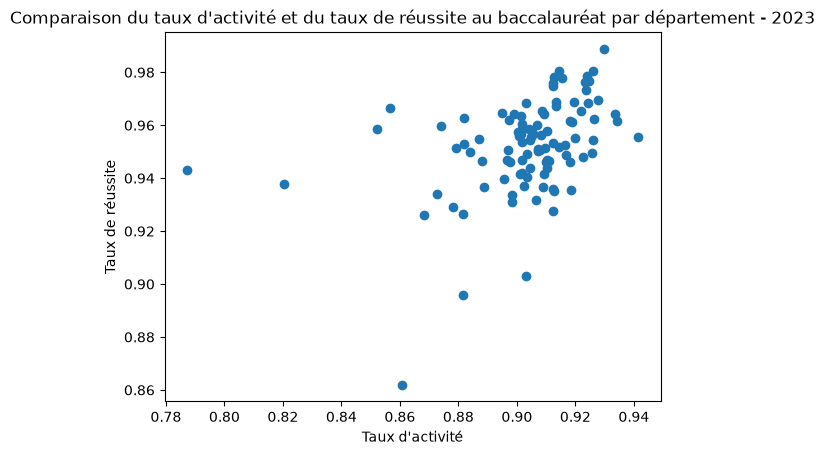

In [40]:
plt.scatter(bac_emploi_2023["Taux d'activité"],bac_emploi_2023["Taux de réussite"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux d'activité et du taux de réussite au baccalauréat par département - 2023")

Le résultat est plus concluant qu'au niveau académie. 

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de passage 2nde-bac au baccalauréat par département - 2023")

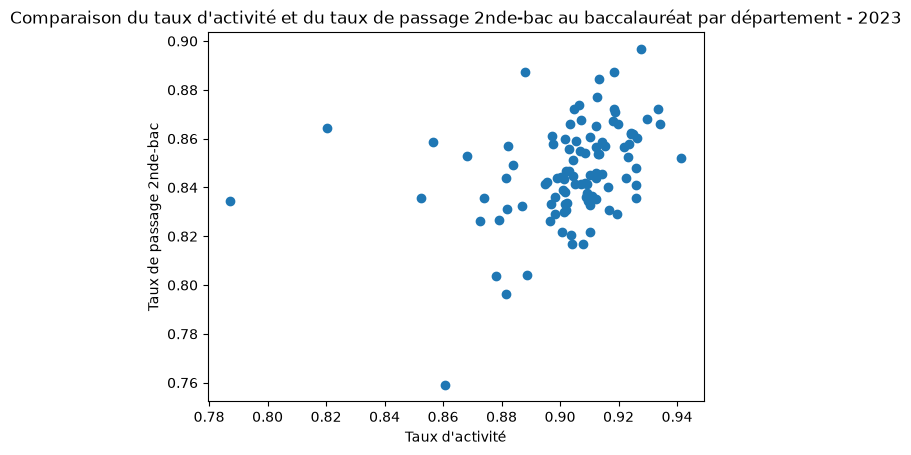

In [44]:
plt.scatter(bac_emploi_2023["Taux d'activité"],bac_emploi_2023["Taux de passage 2nde - bac"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de passage 2nde-bac")
plt.title("Comparaison du taux d'activité et du taux de passage 2nde-bac au baccalauréat par département - 2023")

On teste de comparer le taux d'activité au nombre de mentions.

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de mentions au baccalauréat par département- 2023")

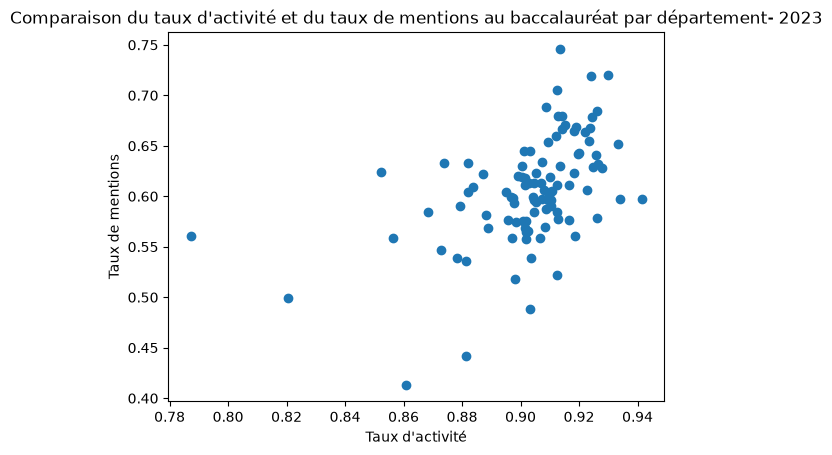

In [43]:
plt.scatter(bac_emploi_2023["Taux d'activité"],bac_emploi_2023["Taux de mentions"])
plt.xlabel("Taux d'activité")
plt.ylabel("Taux de mentions")
plt.title("Comparaison du taux d'activité et du taux de mentions au baccalauréat par département- 2023")

Le résultat est assez similaire.

On se penche désormais sur les données d'inscrits au RSA, également présentes sur le site data.gouv.
On le nettoie pour garder les données intéressantes et le rendre plus facile à manipuler. On reprend l'année 2023, on prend le 1er janvier arbitrairement.

In [46]:
rsa= pd.read_csv("rsa_ppa_s_agg_age_5_dep.csv",sep=";")

rsa=rsa[rsa["Date référence"]=="2023-01-01"]

rsa= rsa.drop(columns=["Nom département","Numéro région","Nom région","Lieu résidence","Date référence"])

rsa =rsa.groupby(["Numéro département","RSA ou PPA"]).agg({"Nombre foyers RSA_PPA":"sum", 
                                                           "Nombre personnes RSA_PPA":"sum"})
rsa = rsa.reset_index()

rsa= rsa[rsa["RSA ou PPA"].isin(["RSA et PA","RSA seul"])]

rsa=rsa.groupby(["Numéro département"]).agg({"Nombre foyers RSA_PPA":"sum", 
                                            "Nombre personnes RSA_PPA":"sum"})
rsa=rsa.reset_index()
rsa.head()

,Numéro département,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA
0,01,7679,15588
1,02,17363,38572
2,03,9794,20099
3,04,4121,7880
4,05,3013,5410


Pour obtenir un taux afin d'augmenter la comparabilité entre des académie de population différente, on rapproche ces données du fichier emploi, où on avait la donnée de population active.

In [51]:
rsa_bac= rsa.merge(
     bac_emploi_2023,
  left_on = ["Numéro département"],
  right_on = ["Code departement"],
  how = "left" 
)

rsa_bac ["Nombre personnes bénéficiant du RSA par actif"]=rsa_bac["Nombre personnes RSA_PPA"]/rsa_bac["Population active"]
rsa_bac.head()

,Numéro département,Nombre foyers RSA_PPA,Nombre personnes RSA_PPA,Code departement,Annee,Presents - Toutes series,Effectif de seconde,Effectif de premiere,Effectif de terminale,Taux de réussite,Taux de mentions,Taux de passage 2nde - bac,Département,Population active,Taux d'activité,Nombre personnes bénéficiant du RSA par actif
0,01,7679,15588,01,2023.0,4713.0,5085.0,4679.0,4804.0,0.947836,0.606446,0.843747,01,332062.20638,0.922580,0.046943
1,02,17363,38572,02,2023.0,3388.0,3801.0,3476.0,3450.0,0.933999,0.546975,0.826077,02,227038.54348,0.872768,0.169892
2,03,9794,20099,03,2023.0,1951.0,2123.0,1855.0,2034.0,0.950661,0.559047,0.833203,03,138249.81493,0.897002,0.145382
3,04,4121,7880,04,2023.0,1119.0,1244.0,1216.0,1159.0,0.956622,0.617784,0.843512,04,71219.69936,0.901411,0.110644
4,05,3013,5410,05,2023.0,912.0,1031.0,971.0,971.0,0.978662,0.719638,0.861974,05,64156.11979,0.924095,0.084326


Text(0.5, 1.0, 'Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département - 2023')

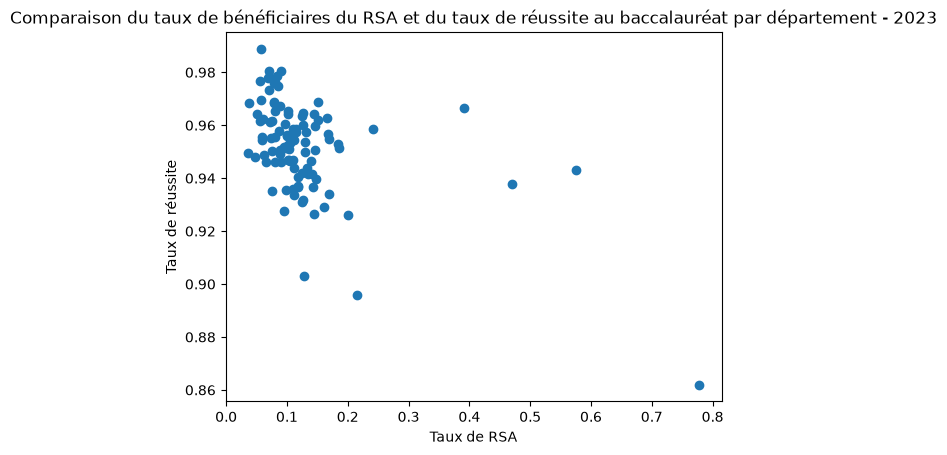

In [58]:
plt.scatter(rsa_bac["Nombre personnes bénéficiant du RSA par actif"],rsa_bac["Taux de réussite"])
plt.xlabel("Taux de RSA")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département - 2023")

On voudrait retirer les valeurs extrêmes. On tente de se concentrer sur la France métropolitaine.

Text(0.5, 1.0, 'Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département métropolitain - 2023')

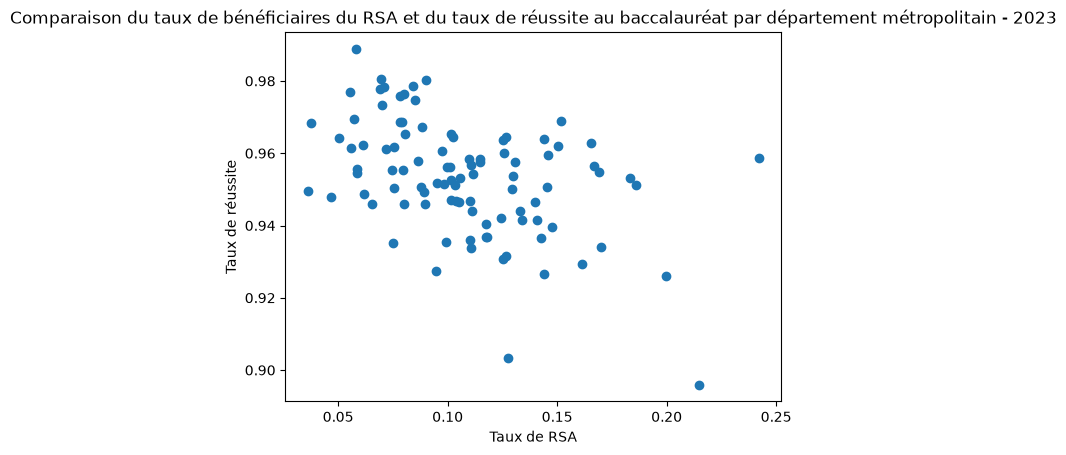

In [59]:
rsa_bac_metropole = rsa_bac[~rsa_bac["Code departement"].isin(["971", "972", "973", "974", "976"])]

plt.scatter(rsa_bac_metropole["Nombre personnes bénéficiant du RSA par actif"],rsa_bac_metropole["Taux de réussite"])
plt.xlabel("Taux de RSA")
plt.ylabel("Taux de réussite")
plt.title("Comparaison du taux de bénéficiaires du RSA et du taux de réussite au baccalauréat par département métropolitain - 2023")

Text(0.5, 1.0, "Comparaison du taux d'activité et du taux de mentions au baccalauréat par département métropolitain - 2023")

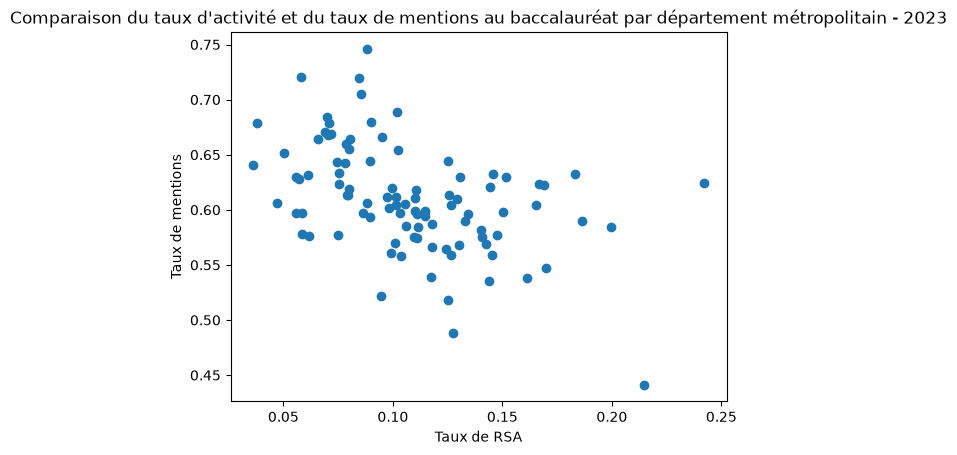

In [60]:
plt.scatter(rsa_bac_metropole["Nombre personnes bénéficiant du RSA par actif"],rsa_bac_metropole["Taux de mentions"])
plt.xlabel("Taux de RSA")
plt.ylabel("Taux de mentions")
plt.title("Comparaison du taux d'activité et du taux de mentions au baccalauréat par département métropolitain - 2023")